In [60]:
# 그래프 관련
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np

# 머신러닝 관련
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

In [61]:
# 도미
bream_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0, 33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0]
bream_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0, 610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0]
# 빙어
smelt_length = [9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
smelt_weight = [6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]

In [62]:
length = bream_length + smelt_length
weight = bream_weight + smelt_weight

# DATA와 LABEL 만들기
# data = [[l,w] for l,w in zip(length, weight)]
data = np.column_stack((length,weight))
label = [1]*35 + [0]*14     #도미 35마리, 빙어 14마리

In [49]:
# # 학습데이터/시험데이터 분리
# train_data,test_data,train_label,test_label = train_test_split(data,label, stratify=label,test_size=0.2)

In [50]:
# clf = KNeighborsClassifier()
# clf.fit(train_data, train_label)
# result = clf.predict(test_data)
# score = clf.score(test_data, test_label)                # 시험데이터가 어느정도 정답 맞췄는지
# # score = metrics.accuracy_score(result, test_label)    # 예측값과 실제정답과의 비교
# print(f'예측률:{score*100}%')

In [51]:
# clf = KNeighborsClassifier()
# clf.fit(train_data, train_label)
# input1 = input('생선의 길이, 무게 입력(예: 25,120)')
# input1 = input1.split(',')
# input2 = list(map(float, input1))   #input2 결과값 형식은 [25.0, 120.0]
# result2 = clf.predict([input2])
# print('예측생선: ', result2)

In [ ]:
# # 정규화
# # 표준점수 = (특성값 - 산술평균) / 표준편차

# mean = np.mean(data, axis=0)
# std = np.std(data, axis=0)
# train_scaled = (data-mean)/std

In [70]:
# 정규화 함수
ss = StandardScaler()
ss.fit(data)
train_scaled = ss.transform(data)

In [71]:
# 정규화 후 학습데이터/시험데이터 분리
train_data,test_data,train_label,test_label = train_test_split(train_scaled,label, stratify=label,test_size=0.2)

In [73]:
# 정규화 후 테스트

clf = KNeighborsClassifier()
clf.fit(train_data, train_label)
# input1 = input('생선의 길이, 무게 입력(예: 25,120)')
# input1 = input1.split(',')
# input2 = list(map(float, input1))   #input2 결과값 형식은 [25.0, 120.0]
# new_input = (input2-mean)/std
# result2 = clf.predict([input2])
# print('예측생선: ', result2)
test_scaled = ss.transform(test_data)
new_scaled = ss.transform([[25,120]])
new_scaled

array([[-0.20271784, -0.99914535]])

In [74]:
# distances, indexes = clf.kneighbors([new_input])
distances,indexes = clf.kneighbors(new_scaled)

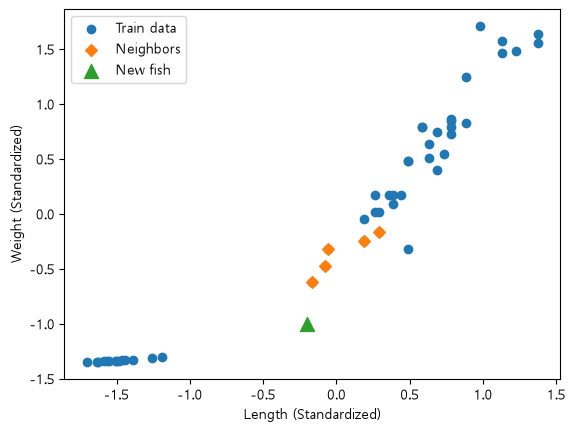

In [75]:
plt.scatter(train_scaled[:,0], train_scaled[:,1], label='Train data')
# plt.scatter(train_scaled[indexes,0], train_scaled[indexes,1], label='Neighbors', marker='D')
plt.scatter(train_data[indexes,0], train_data[indexes,1], label='Neighbors', marker='D')
# plt.scatter(new_input[0], new_input[1], label='New fish', marker='^')
plt.scatter(new_scaled[0, 0], new_scaled[0, 1], marker='^', s=100, label='New fish')
plt.xlabel('Length (Standardized)')
plt.ylabel('Weight (Standardized)')
plt.legend()
plt.show()